# Cell 1: Import thư viện và Cấu hình môi trường

In [1]:
!pip install lightgbm

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
import warnings
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('muted')
warnings.filterwarnings('ignore')

print("Đã tải thành công các thư viện!")

Đã tải thành công các thư viện!


# Cell 2: Tải dữ liệu và Xử lý Ngoại lệ (Outliers)

Kích thước tập Train ban đầu: (1460, 81)
Kích thước tập Test ban đầu: (1459, 80)


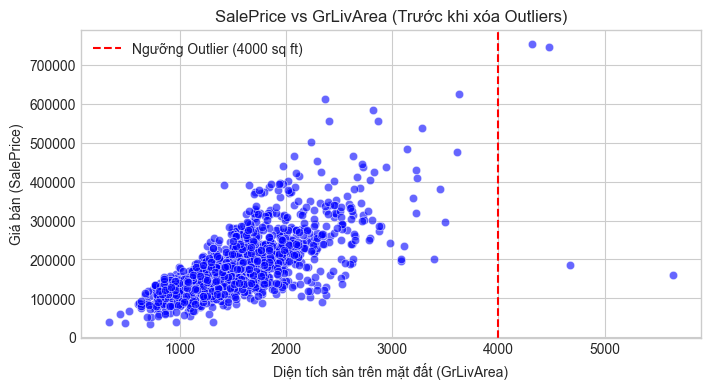

Kích thước tập Train sau khi xóa Outliers: (1456, 81)


In [3]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print(f"Kích thước tập Train ban đầu: {train.shape}")
print(f"Kích thước tập Test ban đầu: {test.shape}")

plt.figure(figsize=(8, 4))
sns.scatterplot(x=train['GrLivArea'], y=train['SalePrice'], color='blue', alpha=0.6)
plt.axvline(x=4000, color='red', linestyle='--', label='Ngưỡng Outlier (4000 sq ft)')
plt.title('SalePrice vs GrLivArea (Trước khi xóa Outliers)')
plt.xlabel('Diện tích sàn trên mặt đất (GrLivArea)')
plt.ylabel('Giá bán (SalePrice)')
plt.legend()
plt.show()

train = train.drop(train[(train['GrLivArea'] > 4000)].index).reset_index(drop=True)
print(f"Kích thước tập Train sau khi xóa Outliers: {train.shape}")

# Cell 3: Phân tích Khám phá Dữ liệu (EDA chuyên sâu)

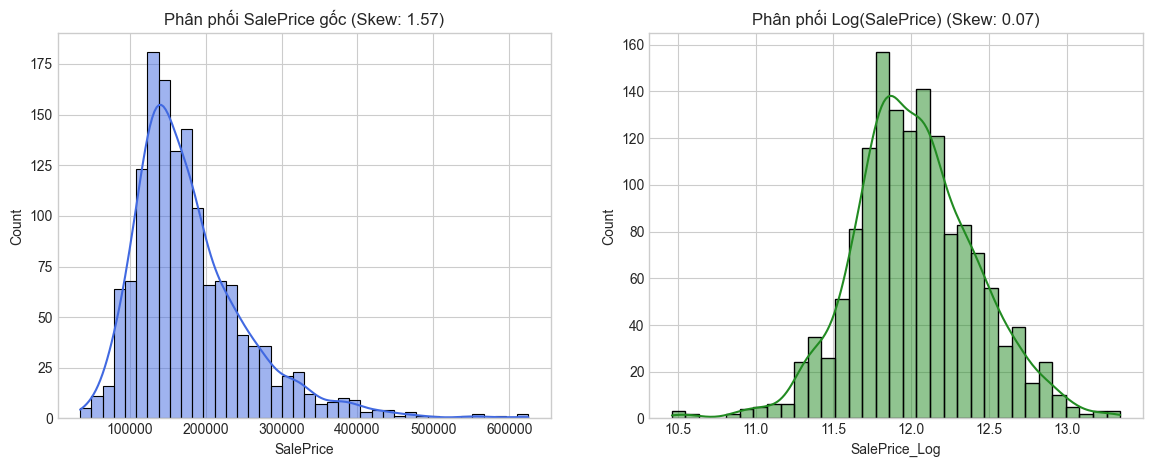

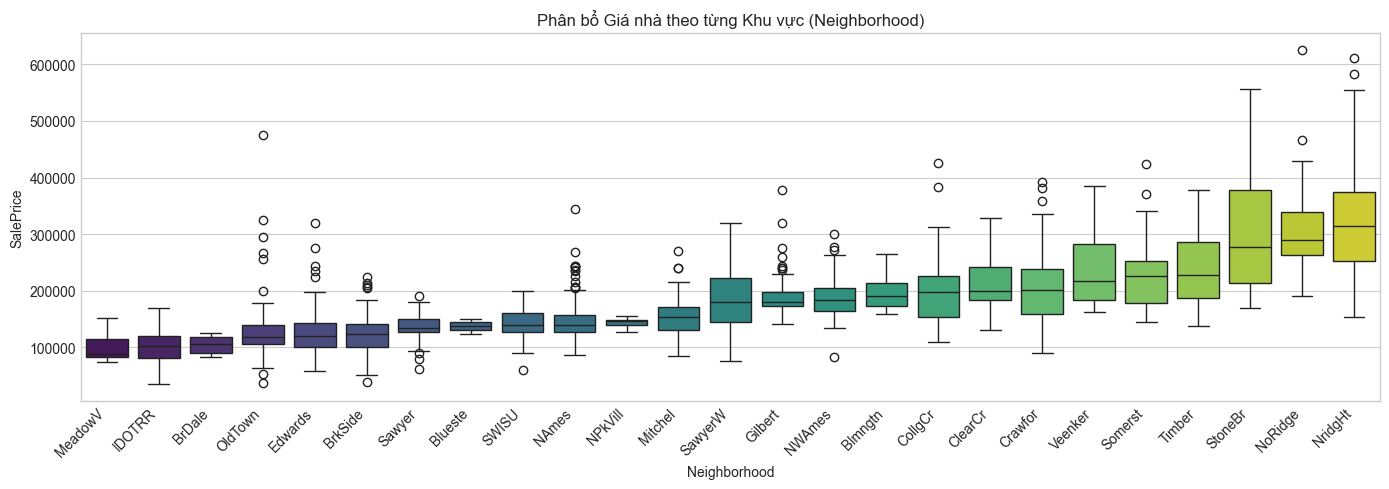

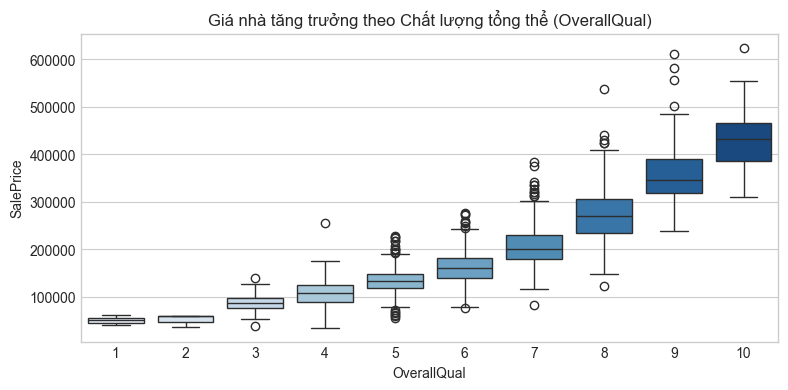

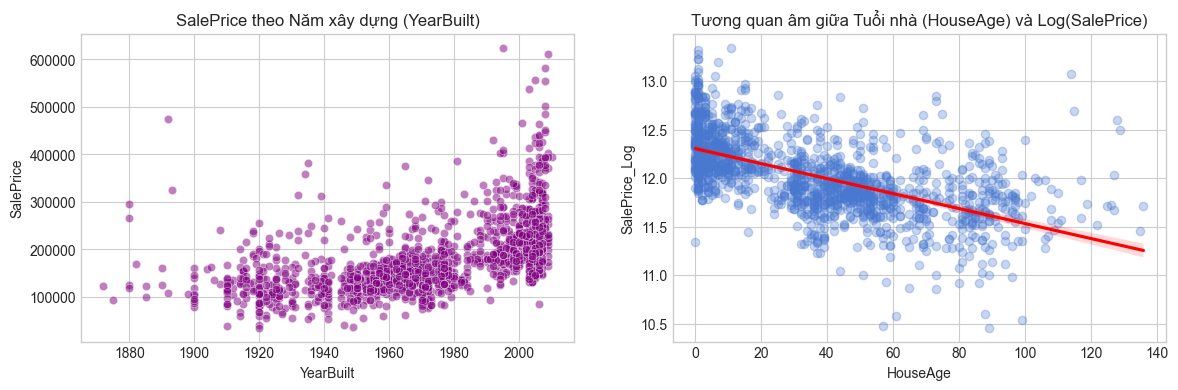

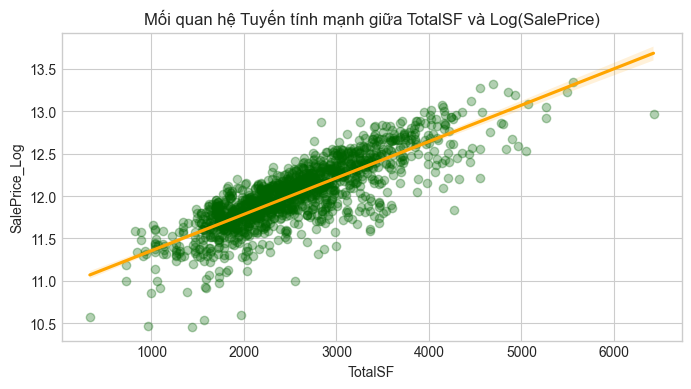

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train['SalePrice'], kde=True, ax=ax1, color='royalblue')
ax1.set_title(f'Phân phối SalePrice gốc (Skew: {train["SalePrice"].skew():.2f})')

train['SalePrice_Log'] = np.log1p(train['SalePrice'])
sns.histplot(train['SalePrice_Log'], kde=True, ax=ax2, color='forestgreen')
ax2.set_title(f'Phân phối Log(SalePrice) (Skew: {train["SalePrice_Log"].skew():.2f})')
plt.show()

plt.figure(figsize=(14, 5))
neigh_order = train.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(x='Neighborhood', y='SalePrice', data=train, order=neigh_order, palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Phân bổ Giá nhà theo từng Khu vực (Neighborhood)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.boxplot(x='OverallQual', y='SalePrice', data=train, palette='Blues')
plt.title('Giá nhà tăng trưởng theo Chất lượng tổng thể (OverallQual)')
plt.show()

train['HouseAge'] = train['YrSold'] - train['YearBuilt']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(x='YearBuilt', y='SalePrice', data=train, alpha=0.5, ax=ax1, color='purple')
ax1.set_title('SalePrice theo Năm xây dựng (YearBuilt)')

sns.regplot(x='HouseAge', y='SalePrice_Log', data=train, scatter_kws={'alpha':0.3}, line_kws={'color':'red'}, ax=ax2)
ax2.set_title('Tương quan âm giữa Tuổi nhà (HouseAge) và Log(SalePrice)')
plt.show()

train['TotalSF'] = train['TotalBsmtSF'] + train['1stFlrSF'] + train['2ndFlrSF']
plt.figure(figsize=(8, 4))
sns.regplot(x='TotalSF', y='SalePrice_Log', data=train, scatter_kws={'alpha':0.3, 'color':'darkgreen'}, line_kws={'color':'orange'})
plt.title('Mối quan hệ Tuyến tính mạnh giữa TotalSF và Log(SalePrice)')
plt.show()

# Cell 4: Tiền xử lý & Điền dữ liệu thiếu (Data Imputation)

In [5]:
y_train = train['SalePrice_Log'].values
train_idx = len(train)

train_features = train.drop(['SalePrice', 'SalePrice_Log', 'HouseAge', 'TotalSF'], axis=1)
test_features = test.copy()

df_all = pd.concat([train_features, test_features], axis=0).reset_index(drop=True)
df_all.drop(['Id'], axis=1, inplace=True)

none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
for col in none_cols:
    df_all[col] = df_all[col].fillna('None')

zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 
             'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for col in zero_cols:
    df_all[col] = df_all[col].fillna(0)

df_all['LotFrontage'] = df_all.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType', 'Utilities']
for col in mode_cols:
    df_all[col] = df_all[col].fillna(df_all[col].mode()[0])

print("Tổng số giá trị thiếu còn lại trong dataset:", df_all.isnull().sum().sum())

Tổng số giá trị thiếu còn lại trong dataset: 2


# Cell 5: Kỹ thuật Tạo đặc trưng mới (Feature Engineering)

In [7]:
df_all['TotalSF'] = df_all['TotalBsmtSF'] + df_all['1stFlrSF'] + df_all['2ndFlrSF']
df_all['TotalBath'] = df_all['FullBath'] + (0.5 * df_all['HalfBath']) + df_all['BsmtFullBath'] + (0.5 * df_all['BsmtHalfBath'])
df_all['HouseAge'] = df_all['YrSold'] - df_all['YearBuilt']
df_all['RemodAge'] = df_all['YrSold'] - df_all['YearRemodAdd']

df_all['IsRemodeled'] = (df_all['YearBuilt'] != df_all['YearRemodAdd']).astype(int)
df_all['HasGarage'] = (df_all['GarageArea'] > 0).astype(int)
df_all['HasBsmt'] = (df_all['TotalBsmtSF'] > 0).astype(int)
df_all['HasFireplace'] = (df_all['Fireplaces'] > 0).astype(int)

numeric_feats = df_all.select_dtypes(include=[np.number]).columns
skewed_feats = df_all[numeric_feats].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
high_skew = skewed_feats[abs(skewed_feats) > 0.75].index

for feat in high_skew:
    df_all[feat] = np.log1p(df_all[feat])

df_all = pd.get_dummies(df_all)

X_train = df_all.iloc[:train_idx, :].copy()
X_test = df_all.iloc[train_idx:, :].copy()

print(f"Kích thước Ma trận X_train: {X_train.shape}")
print(f"Kích thước Ma trận X_test: {X_test.shape}")

Kích thước Ma trận X_train: (1456, 309)
Kích thước Ma trận X_test: (1459, 309)


# Cell 6: Huấn luyện Mô hình & Đánh giá Cross-Validation

In [ ]:
n_folds = 5

def rmse_cv(model):
    kf = KFold(n_folds, shuffle=True, random_state=42)
    rmse = np.sqrt(-cross_val_score(model, X_train, y_train, scoring="neg_mean_squared_error", cv=kf))
    return rmse

model_ridge = Ridge(alpha=15.0, random_state=42)

model_lgb = lgb.LGBMRegressor(
    objective='regression',
    num_leaves=31,
    learning_rate=0.03,
    n_estimators=1000,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=42,
    verbose=-1
)

score_ridge = rmse_cv(model_ridge)
print(f"[Cross-Validation] Ridge RMSE Score:    {score_ridge.mean():.4f} (± {score_ridge.std():.4f})")

score_lgb = rmse_cv(model_lgb)
print(f"[Cross-Validation] LightGBM RMSE Score: {score_lgb.mean():.4f} (± {score_lgb.std():.4f})")

[Cross-Validation] Ridge RMSE Score:    0.1126 (± 0.0081)
[Cross-Validation] LightGBM RMSE Score: 0.1206 (± 0.0099)


# Cell 7: Dự đoán Blend & Xuất file Submission

In [ ]:
model_ridge.fit(X_train, y_train)
model_lgb.fit(X_train, y_train)

preds_ridge = np.expm1(model_ridge.predict(X_test))
preds_lgb = np.expm1(model_lgb.predict(X_test))

final_predictions = (0.3 * preds_ridge) + (0.7 * preds_lgb)

submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': final_predictions
})

submission.to_csv('submission.csv', index=False)
print("-> Đã xuất thành công file 'submission.csv'!")
submission.head()

-> Đã xuất thành công file 'submission.csv'!


,Id,SalePrice
0,1461,121874.165228
1,1462,159908.773991
2,1463,186536.106047
3,1464,197025.952031
4,1465,187669.791744
